<a href="https://colab.research.google.com/github/Phoenix05420/language-identification-05/blob/main/Language_Identification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Language Identification using LSTM (TensorFlow/Keras)
Tasks: load & preprocess → tokenize & pad → LSTM model → train & evaluate (Accuracy, Precision, Recall, F1).

## Task 1: Load the dataset, handle missing values, preprocess text

In [ ]:
!pip install -q kagglehub

import re, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import kagglehub, os, glob
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

In [ ]:
# Download dataset from Kaggle (public dataset; no API key usually needed with kagglehub)
path = kagglehub.dataset_download("zarajamshaid/language-identification-datasst")
print("Downloaded to:", path)

csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print("CSV files:", csv_files)

df = pd.read_csv(csv_files[0])
print(df.shape)
df.head()

Using Colab cache for faster access to the 'language-identification-datasst' dataset.
Downloaded to: /kaggle/input/language-identification-datasst
CSV files: ['/kaggle/input/language-identification-datasst/dataset.csv']
(22000, 2)


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [ ]:
# Detect text and label columns automatically
cols = {c.lower(): c for c in df.columns}
TEXT_COL = cols.get("text", df.columns[0])
LABEL_COL = cols.get("language", cols.get("label", df.columns[-1]))
df = df[[TEXT_COL, LABEL_COL]].rename(columns={TEXT_COL: "text", LABEL_COL: "language"})

print("Missing values before:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

# Handle missing values / duplicates / empty strings
df = df.dropna(subset=["text", "language"]).drop_duplicates()
df["text"] = df["text"].astype(str)
df = df[df["text"].str.strip() != ""]
print("\nMissing values after:\n", df.isnull().sum())
print("Shape:", df.shape)

Missing values before:
 text        0
language    0
dtype: int64
Duplicates: 141

Missing values after:
 text        0
language    0
dtype: int64
Shape: (21858, 2)


Subset size: 11000 | Languages: 22


/tmp/ipykernel_522/3558805329.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), N_PER_LANG), random_state=SEED))


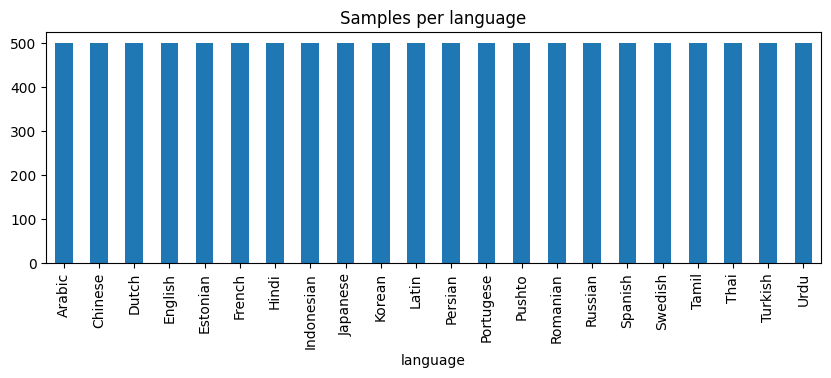

In [ ]:
# Text preprocessing: lowercase, remove digits/URLs, normalise whitespace.
# (Punctuation/accents are kept: they carry strong language signals.)
def clean_text(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"\d+", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

df["clean"] = df["text"].apply(clean_text)
df = df[df["clean"] != ""]

# Manageable subset: max 500 samples per language
N_PER_LANG = 500
df = (df.groupby("language", group_keys=False)
        .apply(lambda g: g.sample(min(len(g), N_PER_LANG), random_state=SEED))
        .reset_index(drop=True))

print("Subset size:", len(df), "| Languages:", df["language"].nunique())
df["language"].value_counts().plot(kind="bar", figsize=(10,3), title="Samples per language")
plt.show()

## Task 2: Tokenize and pad sequences
Character-level tokenization works best for language ID (handles all scripts, no word segmentation needed).

In [ ]:
# Encode labels
le = LabelEncoder()
y = le.fit_transform(df["language"])
num_classes = len(le.classes_)

# Train / validation / test split (70/15/15, stratified)
X_train, X_temp, y_train, y_temp = train_test_split(df["clean"], y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

# Character-level tokenizer (fit on training data only)
tokenizer = Tokenizer(char_level=True, oov_token="<OOV>", lower=False)
tokenizer.fit_on_texts(X_train)
vocab_size = len(tokenizer.word_index) + 1
print("Vocabulary size:", vocab_size)

# Choose max length from the 95th percentile of text lengths
MAX_LEN = int(np.percentile(X_train.str.len(), 95))
print("MAX_LEN:", MAX_LEN)

def to_padded(texts):
    return pad_sequences(tokenizer.texts_to_sequences(texts), maxlen=MAX_LEN, padding="post", truncating="post")

X_train_p, X_val_p, X_test_p = to_padded(X_train), to_padded(X_val), to_padded(X_test)
print(X_train_p.shape, X_val_p.shape, X_test_p.shape)

Vocabulary size: 5734
MAX_LEN: 876
(7700, 876) (1650, 876) (1650, 876)


## Task 3: LSTM model

In [ ]:
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, mask_zero=True),
    Bidirectional(LSTM(64)),
    Dropout(0.4),
    Dense(256, activation="relu"),
    Dropout(0.4),
    Dense(num_classes, activation="softmax"),
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, MAX_LEN))
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 876, 64)        │       366,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 22)             │         5,654 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 471,702 (1.80 MB)

 Trainable params: 471,702 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

## Task 4: Train and evaluate

In [ ]:
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(
    X_train_p, y_train,
    validation_data=(X_val_p, y_val),
    epochs=45, batch_size=36,
    callbacks=[early_stop], verbose=1
)

Epoch 1/45
214/214 ━━━━━━━━━━━━━━━━━━━━ 14s 56ms/step - accuracy: 0.3461 - loss: 1.9550 - val_accuracy: 0.5521 - val_loss: 1.2136
Epoch 2/45
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.5825 - loss: 1.1652 - val_accuracy: 0.7042 - val_loss: 0.8882
Epoch 3/45
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.6210 - loss: 1.1158 - val_accuracy: 0.7261 - val_loss: 0.7702
Epoch 4/45
214/214 ━━━━━━━━━━━━━━━━━━━━ 20s 93ms/step - accuracy: 0.6926 - loss: 0.8474 - val_accuracy: 0.7624 - val_loss: 0.6611
Epoch 5/45
214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - accuracy: 0.7403 - loss: 0.7395 - val_accuracy: 0.7321 - val_loss: 0.7278
Epoch 6/45
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.7481 - loss: 0.7243 - val_accuracy: 0.7970 - val_loss: 0.5806
Epoch 7/45
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.7347 - loss: 0.7755 - val_accuracy: 0.7806 - val_loss: 0.6374
Epoch 8/45
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.7853 - loss: 0.6289 - 

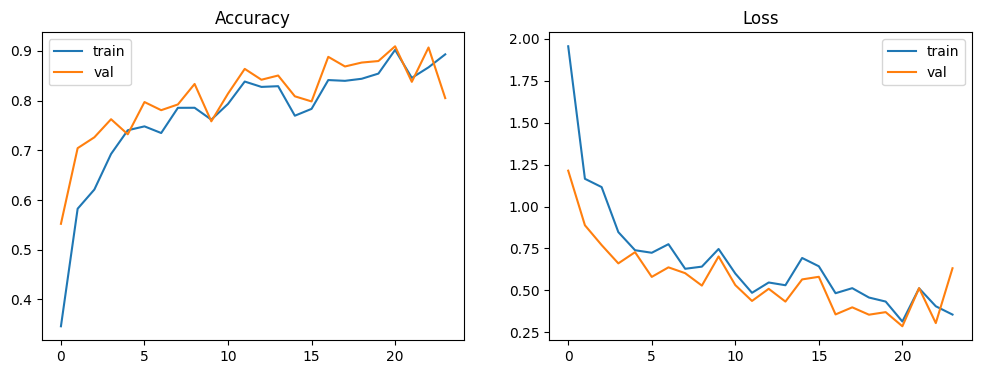

In [ ]:
# Training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train"); ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train"); ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

In [ ]:
# Evaluate on the test set
y_pred = np.argmax(model.predict(X_test_p), axis=1)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average='weighted', zero_division=0):.4f}  (weighted)")
print(f"Recall   : {recall_score(y_test, y_pred, average='weighted', zero_division=0):.4f}  (weighted)")
print(f"F1-score : {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}  (weighted)")
print(f"Macro F1 : {f1_score(y_test, y_pred, average='macro', zero_division=0):.4f}")

print("\nPer-class report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step
Accuracy : 0.9030
Precision: 0.9176  (weighted)
Recall   : 0.9030  (weighted)
F1-score : 0.9037  (weighted)
Macro F1 : 0.9037

Per-class report:

              precision    recall  f1-score   support

      Arabic       1.00      0.97      0.99        75
     Chinese       0.97      0.97      0.97        75
       Dutch       0.93      0.49      0.64        75
     English       0.54      0.95      0.69        75
    Estonian       0.91      0.69      0.79        75
      French       0.92      0.93      0.93        75
       Hindi       1.00      0.97      0.99        75
  Indonesian       0.84      0.87      0.86        75
    Japanese       1.00      1.00      1.00        75
      Korean       1.00      1.00      1.00        75
       Latin       0.86      0.75      0.80        75
     Persian       0.97      0.99      0.98        75
   Portugese       0.72      0.77      0.75        75
      Pushto       0.97      0.91      0.94        75
   

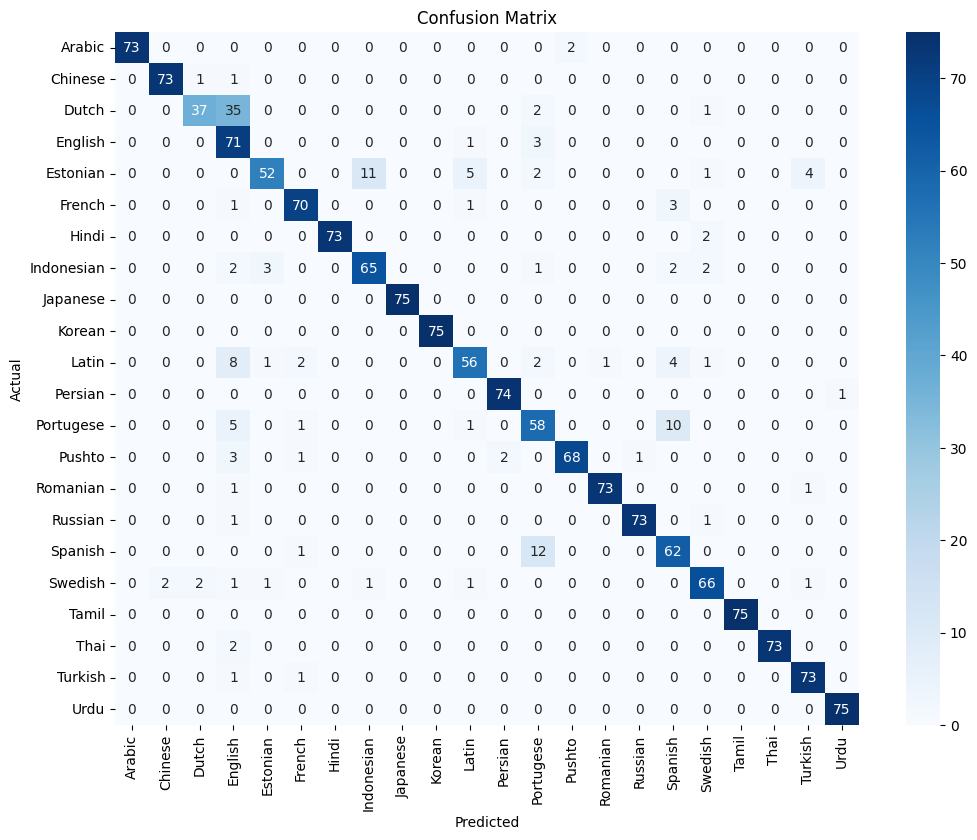

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

In [ ]:
# Try it on new text
def predict_language(text):
    seq = to_padded([clean_text(text)])
    probs = model.predict(seq, verbose=0)[0]
    i = np.argmax(probs)
    return le.classes_[i], float(probs[i])

for s in ["Hello, how are you today?",
          "Bonjour, comment allez-vous aujourd'hui ?",
          "Hola, ¿cómo estás hoy?",
          "Guten Morgen, wie geht es dir?",
          "வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?"]:
    print(s, "->", predict_language(s))

Hello, how are you today? -> ('English', 0.7247703671455383)
Bonjour, comment allez-vous aujourd'hui ? -> ('Latin', 0.9858875870704651)
Hola, ¿cómo estás hoy? -> ('Portugese', 0.7531211376190186)
Guten Morgen, wie geht es dir? -> ('Dutch', 0.623579204082489)
வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்? -> ('Tamil', 0.9999977350234985)
